# BikePulse: Urban Micromobility Hourly Demand Forecasting
**DataTalks.Club Machine Learning Zoomcamp 2026 — Midterm Project**

## 1. Problem Overview & Dataset Provenance
Urban bikeshare operators must keep bikes available at residential origin docks before morning rush hour while preventing dock saturation near downtown offices. Under-provisioning loses trips, while reactive van dispatches drive up operating costs.

In this notebook we:
1. Audit and clean the **UCI #275 Capital Bikeshare Hourly Dataset** (`17,379` hourly observations from Washington D.C., 2011–2012, enriched with Freemeteo weather telemetry).
2. Perform extensive **Exploratory Data Analysis (EDA)** covering distributions, sensor anomalies, missing timestamps (including **Hurricane Sandy**), correlations, mutual information, and temporal/weather interactions.
3. Design leakage-free domain & cyclical features with `DictVectorizer`.
4. Train and tune **four distinct model families** (**Ridge Regression**, **Decision Tree**, **Random Forest**, and **XGBoost**) on a strict 60% / 20% / 20% split, then evaluate our final model on the held-out Test set.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

from model import (
    RAW_FEATURE_COLUMNS,
    SEASON_MAP,
    TARGET_COLUMN,
    WEATHER_MAP,
    compute_training_defaults,
    dataframe_to_feature_dicts,
    postprocess_predictions,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 130

IMAGES_DIR = Path("docs/images")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("data/bike_sharing_hour.csv")
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset shape: 17,379 rows x 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### 1.1 Schema, Ranges, Sensor Anomalies & Target Leakage Check
Before modeling, we inspect column types, missing values, value ranges, timestamp completeness, and verify that `casual + registered == cnt` (confirming both sub-counts must be excluded to prevent target leakage).

In [2]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "null_count": df.isna().sum(),
    "n_unique": df.nunique(),
    "min": df.min(numeric_only=False),
    "max": df.max(numeric_only=False),
})
display(summary)

# Verify exact additive leakage identity
leakage_exact = int((df["casual"] + df["registered"] == df["cnt"]).sum())
print(f"Rows where casual + registered == cnt: {leakage_exact:,} / {len(df):,} (100% -> MUST DROP)")

# Sensor anomaly check: 0% relative humidity hours
zero_hum = df[df["hum"] == 0]
print(f"Zero-humidity sensor fault rows: {len(zero_hum)} (dates: {zero_hum['dteday'].unique().tolist()})")

# Temporal completeness check (24h x 731 days = 17,544 expected hours)
hours_per_day = df.groupby("dteday")["hr"].count()
sparse_days = hours_per_day[hours_per_day < 18].sort_values()
print("\nDays with major service outages / missing hourly logs (<18 recorded hours):")
print(sparse_days)

,dtype,null_count,n_unique,min,max
instant,int64,0,17379,1,17379
dteday,str,0,731,2011-01-01,2012-12-31
season,int64,0,4,1,4
yr,int64,0,2,0,1
mnth,int64,0,12,1,12
hr,int64,0,24,0,23
holiday,int64,0,2,0,1
weekday,int64,0,7,0,6
workingday,int64,0,2,0,1
weathersit,int64,0,4,1,4


Rows where casual + registered == cnt: 17,379 / 17,379 (100% -> MUST DROP)
Zero-humidity sensor fault rows: 22 (dates: ['2011-03-10'])

Days with major service outages / missing hourly logs (<18 recorded hours):
dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
2011-01-18    12
2011-01-26    16
2011-08-28    17
Name: hr, dtype: int64


**Key Data Quality Insights:**
* **Zero null cells**, but **165 missing hourly slots** out of `731 x 24 = 17,544` calendar hours — most dramatically `2012-10-29` (`1` hour) and `2012-10-30` (`11` hours) when **Hurricane Sandy** shut down Washington D.C. transit.
* **Sensor anomaly:** `22` consecutive hours on `2011-03-10` report `hum == 0.0` despite light rain (`weathersit == 3`). Our preprocessing pipeline imputes `hum <= 0` using the training-set median (`0.62`).
* **Strict Leakage Guard:** `casual` and `registered` sum identically to `cnt` on all `17,379` rows and are excluded alongside `instant` and `dteday`.

---
## 2. Exploratory Data Analysis (EDA)
### 2.1 Target Variable (`cnt`) Distribution & Log Transformation

Target (`cnt`) quantiles:
0.01      2.0
0.10      9.0
0.25     40.0
0.50    142.0
0.75    281.0
0.90    451.2
0.99    782.2
Name: cnt, dtype: float64
Raw skewness: 1.277 | log1p(cnt) skewness: -0.818


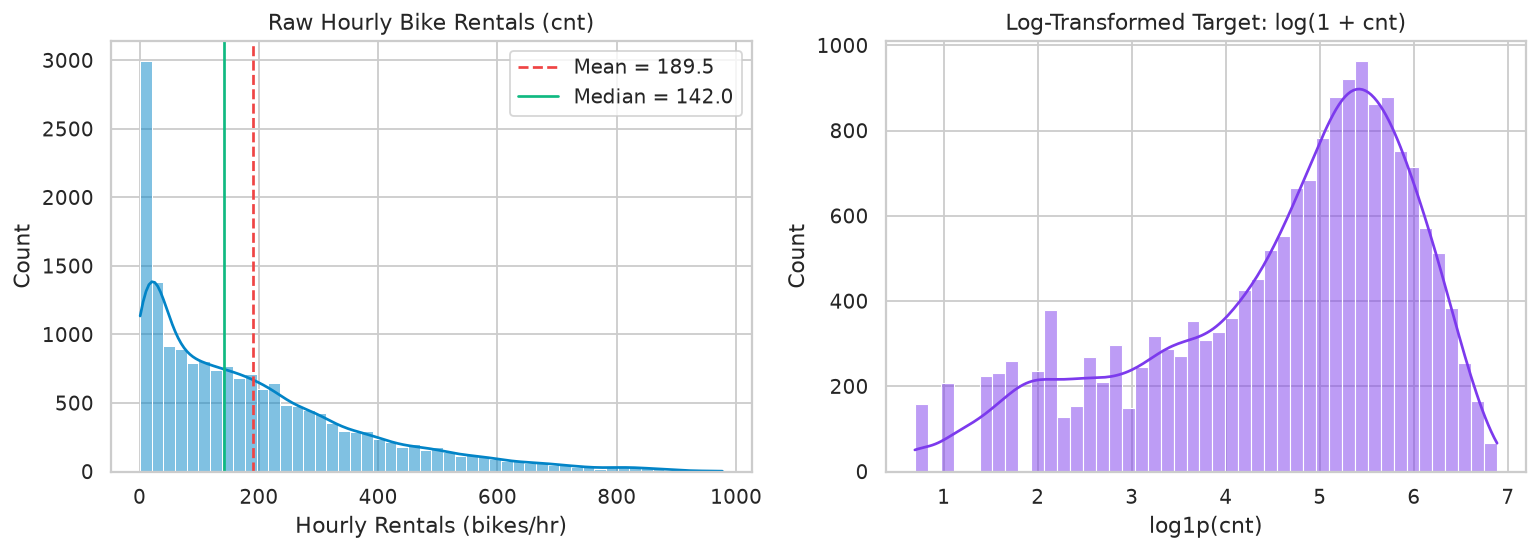

In [3]:
print("Target (`cnt`) quantiles:")
print(df["cnt"].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).round(1))
print(f"Raw skewness: {df['cnt'].skew():.3f} | log1p(cnt) skewness: {np.log1p(df['cnt']).skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
sns.histplot(df["cnt"], bins=50, kde=True, color="#0284c7", ax=axes[0])
axes[0].axvline(df["cnt"].mean(), color="#ef4444", linestyle="--", label=f"Mean = {df['cnt'].mean():.1f}")
axes[0].axvline(df["cnt"].median(), color="#10b981", linestyle="-", label=f"Median = {df['cnt'].median():.1f}")
axes[0].set_title("Raw Hourly Bike Rentals (cnt)")
axes[0].set_xlabel("Hourly Rentals (bikes/hr)")
axes[0].legend()

sns.histplot(np.log1p(df["cnt"]), bins=45, kde=True, color="#7c3aed", ax=axes[1])
axes[1].set_title("Log-Transformed Target: log(1 + cnt)")
axes[1].set_xlabel("log1p(cnt)")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "eda_target_distribution.png", bbox_inches="tight")
plt.show()

### 2.2 Temporal, Commuter & Weather Regime Patterns
Hourly bike demand exhibits a sharp **interaction** between `hr` and `workingday`: working days show bimodal commuter spikes at **08:00** and **17:00–18:00**, whereas weekends peak broadly between **12:00 and 16:00**.

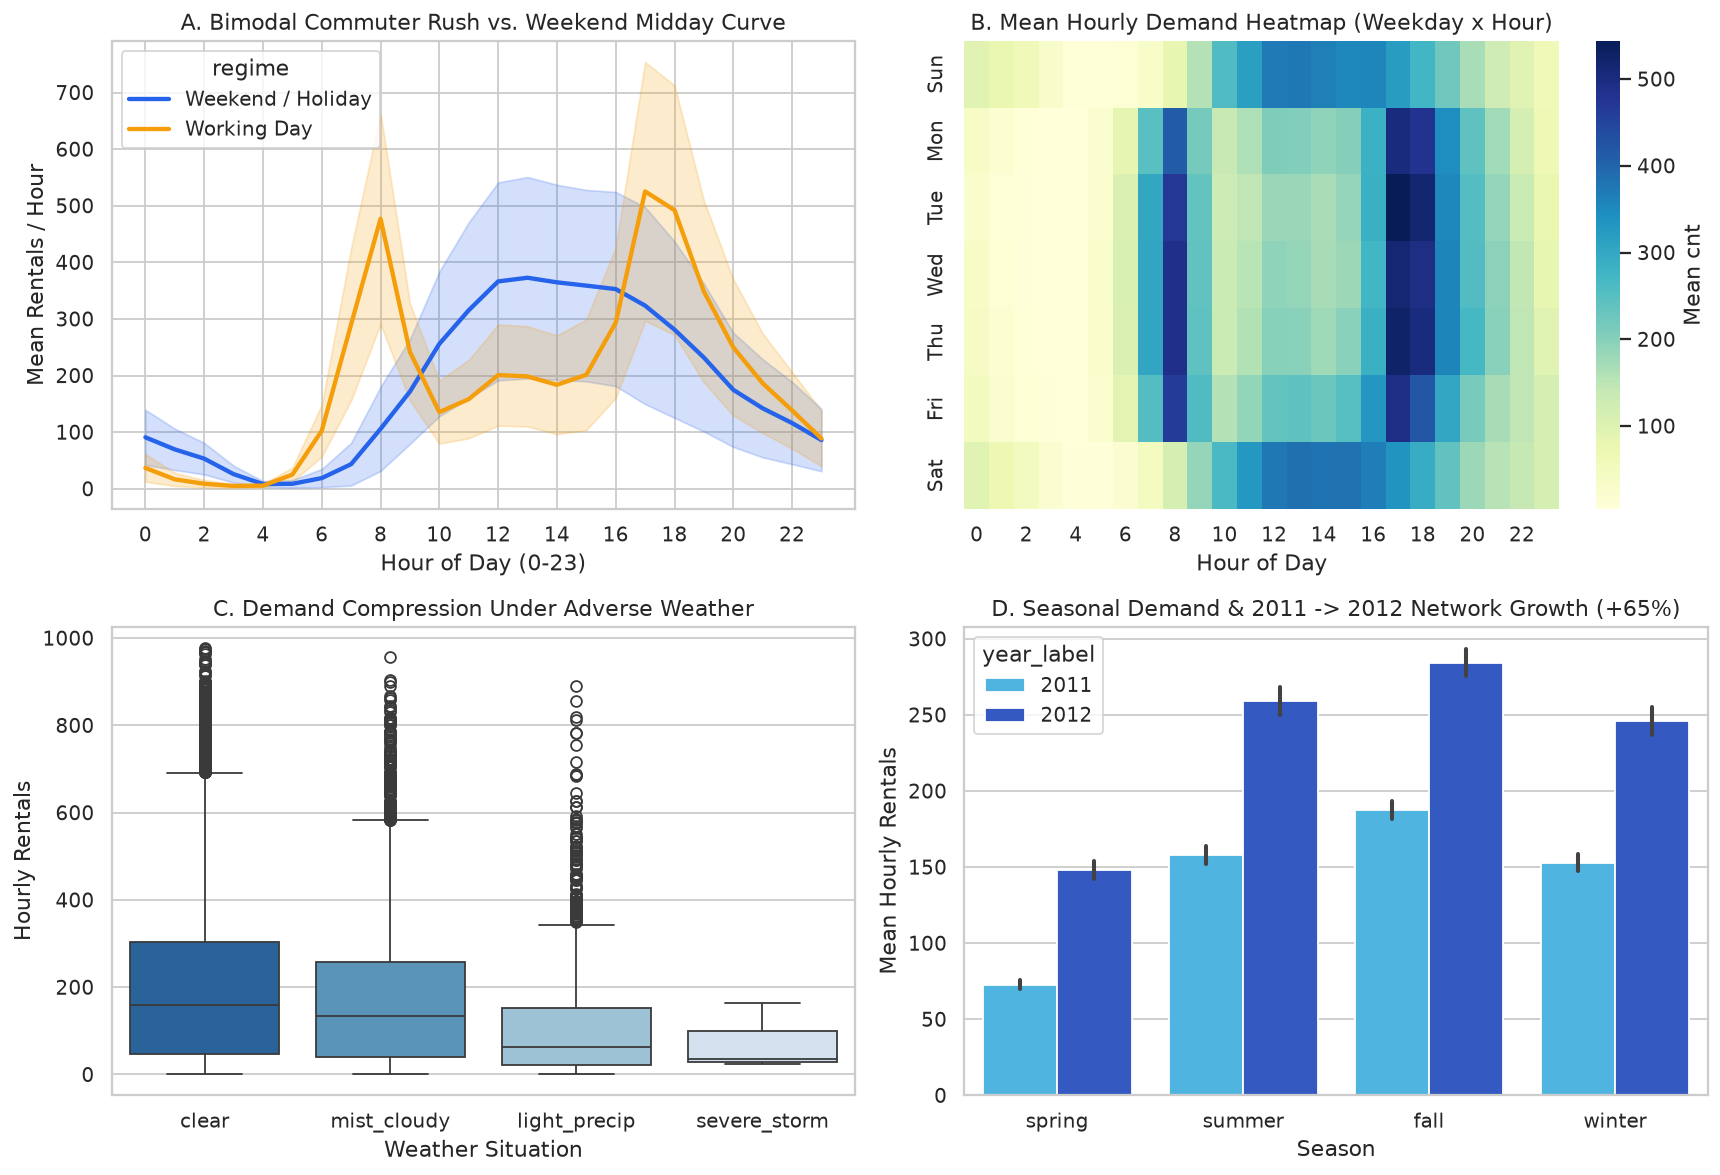

In [4]:
eda_df = df.copy()
eda_df["season_label"] = eda_df["season"].map(SEASON_MAP)
eda_df["weather_label"] = eda_df["weathersit"].map(WEATHER_MAP)
eda_df["regime"] = np.where(eda_df["workingday"] == 1, "Working Day", "Weekend / Holiday")
eda_df["year_label"] = eda_df["yr"].map({0: "2011", 1: "2012"})

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))

sns.lineplot(
    data=eda_df, x="hr", y="cnt", hue="regime", estimator="mean",
    errorbar="sd", linewidth=2.4, palette=["#2563eb", "#f59e0b"], ax=axes[0, 0]
)
axes[0, 0].set_title("A. Bimodal Commuter Rush vs. Weekend Midday Curve")
axes[0, 0].set_xlabel("Hour of Day (0-23)")
axes[0, 0].set_ylabel("Mean Rentals / Hour")
axes[0, 0].set_xticks(range(0, 24, 2))

pivot = eda_df.pivot_table(index="weekday", columns="hr", values="cnt", aggfunc="mean")
pivot.index = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sns.heatmap(pivot, cmap="YlGnBu", ax=axes[0, 1], cbar_kws={"label": "Mean cnt"})
axes[0, 1].set_title("B. Mean Hourly Demand Heatmap (Weekday x Hour)")
axes[0, 1].set_xlabel("Hour of Day")

sns.boxplot(
    data=eda_df, x="weather_label", y="cnt",
    order=["clear", "mist_cloudy", "light_precip", "severe_storm"],
    palette="Blues_r", ax=axes[1, 0]
)
axes[1, 0].set_title("C. Demand Compression Under Adverse Weather")
axes[1, 0].set_xlabel("Weather Situation")
axes[1, 0].set_ylabel("Hourly Rentals")

sns.barplot(
    data=eda_df, x="season_label", y="cnt", hue="year_label",
    order=["spring", "summer", "fall", "winter"], palette=["#38bdf8", "#1d4ed8"], ax=axes[1, 1]
)
axes[1, 1].set_title("D. Seasonal Demand & 2011 -> 2012 Network Growth (+65%)")
axes[1, 1].set_xlabel("Season")
axes[1, 1].set_ylabel("Mean Hourly Rentals")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "eda_temporal_weather.png", bbox_inches="tight")
plt.show()

### 2.3 Feature Importance Analysis: Correlations & Mutual Information
Linear correlation captures monotonic effects (`temp`, `hum`), but severely understates cyclical variables like `hr` ($r = 0.39$ linearly, yet highest non-linear Mutual Information!). We compute both on the **training split** to avoid data snooping.

Split sizes -> Train: 10,427 | Val: 3,476 | Test: 3,476


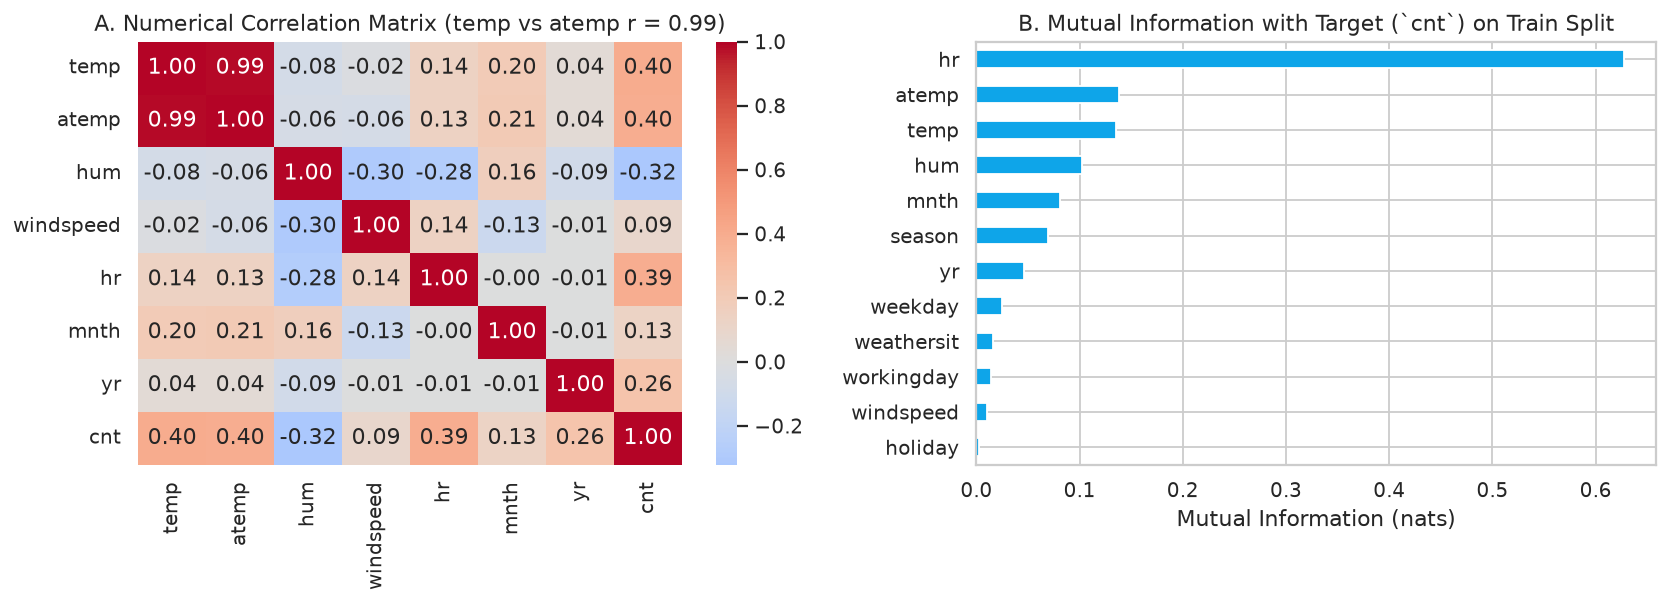

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.20, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)
print(f"Split sizes -> Train: {len(df_train):,} | Val: {len(df_val):,} | Test: {len(df_test):,}")

num_cols = ["temp", "atemp", "hum", "windspeed", "hr", "mnth", "yr", "cnt"]
corr_matrix = df_train[num_cols].corr()

discrete_mask = [col in ("season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit")
                 for col in RAW_FEATURE_COLUMNS]
mi_scores = mutual_info_regression(
    df_train[list(RAW_FEATURE_COLUMNS)],
    df_train[TARGET_COLUMN],
    discrete_features=discrete_mask,
    random_state=42,
)
mi_series = pd.Series(mi_scores, index=RAW_FEATURE_COLUMNS).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("A. Numerical Correlation Matrix (temp vs atemp r = 0.99)")

mi_series.plot(kind="barh", color="#0ea5e9", ax=axes[1])
axes[1].set_title("B. Mutual Information with Target (`cnt`) on Train Split")
axes[1].set_xlabel("Mutual Information (nats)")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "eda_correlations_mi.png", bbox_inches="tight")
plt.show()

---
## 3. Feature Engineering & Validation Setup
Guided by EDA, `model.engineer_record` constructs:
* **Categorical interaction & bucket features** (`regime_hour`, `hour_bucket`, `season_name`, `weather_condition`, `weekday_name`, `day_regime`) so linear models can also capture commuter-vs-weekend hourly profiles.
* **Cyclical encodings** (`hr_sin`, `hr_cos`, `mnth_sin`, `mnth_cos`) so hour `23` and hour `0` remain adjacent.
* **Domain comfort & rush indicators** (`thermal_comfort`, `weather_severity_wind`, `is_morning_rush`, `is_evening_rush`, `is_night`) plus training-median imputation for zero-humidity sensor faults.

In [6]:
train_defaults = compute_training_defaults(df_train)
dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(dataframe_to_feature_dicts(df_train, train_defaults))
X_val = dv.transform(dataframe_to_feature_dicts(df_val, train_defaults))

y_train = df_train[TARGET_COLUMN].to_numpy(dtype=float)
y_train_log = np.log1p(y_train)
y_val = df_val[TARGET_COLUMN].to_numpy(dtype=float)
y_test = df_test[TARGET_COLUMN].to_numpy(dtype=float)

print(f"Encoded feature matrix: X_train={X_train.shape}, X_val={X_val.shape}")


def score_preds(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "RMSE": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
        "MAE": round(float(mean_absolute_error(y_true, y_pred)), 3),
        "R2": round(float(r2_score(y_true, y_pred)), 4),
    }

Encoded feature matrix: X_train=(10427, 133), X_val=(3476, 133)


---
## 4. Model Training & Hyperparameter Tuning
We train and systematically tune **four model families**:
1. **Ridge Regression** (linear model — tuning regularization `alpha` and target transform `raw` vs `log1p`).
2. **DecisionTreeRegressor** (single tree — tuning `max_depth` x `min_samples_leaf`).
3. **RandomForestRegressor** (bagging ensemble — tuning `max_depth` x `n_estimators`).
4. **XGBRegressor** (gradient boosting — tuning `learning_rate`, `max_depth`, and `min_child_weight`).

In [7]:
# 4.1 Ridge Regression Tuning
ridge_rows = []
for mode in ("raw", "log1p"):
    for alpha in (0.01, 0.1, 1.0, 10.0, 50.0, 100.0):
        m = Ridge(alpha=alpha)
        m.fit(X_train, y_train_log if mode == "log1p" else y_train)
        raw_p = m.predict(X_val)
        preds = postprocess_predictions(raw_p) if mode == "log1p" else np.maximum(raw_p, 0.0)
        ridge_rows.append({"target": mode, "alpha": alpha, **score_preds(y_val, preds)})

ridge_df = pd.DataFrame(ridge_rows).sort_values("RMSE")
print("Top Ridge configurations:")
display(ridge_df.head(5))
best_ridge = ridge_df.iloc[0]

Top Ridge configurations:


,target,alpha,RMSE,MAE,R2
6,log1p,0.01,67.933,40.290,0.8581
7,log1p,0.10,67.957,40.293,0.8580
8,log1p,1.00,68.179,40.345,0.8570
10,log1p,50.00,68.895,41.746,0.8540
9,log1p,10.00,69.037,40.804,0.8534


In [8]:
# 4.2 Decision Tree Tuning (max_depth x min_samples_leaf)
dt_rows = []
for max_depth in (6, 8, 10, 12, 15, 20, None):
    for min_leaf in (1, 5, 10, 20):
        dt = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf, random_state=42)
        dt.fit(X_train, y_train_log)
        preds = postprocess_predictions(dt.predict(X_val))
        dt_rows.append({"max_depth": str(max_depth), "min_samples_leaf": min_leaf, **score_preds(y_val, preds)})

dt_df = pd.DataFrame(dt_rows).sort_values("RMSE")
print("Top Decision Tree configurations:")
display(dt_df.head(5))
best_dt = dt_df.iloc[0]

Top Decision Tree configurations:


,max_depth,min_samples_leaf,RMSE,MAE,R2
22,20,10,55.171,33.683,0.9064
26,None,10,55.177,33.629,0.9064
21,20,5,56.508,34.387,0.9018
25,None,5,56.674,34.507,0.9012
18,15,10,56.922,35.006,0.9004


In [9]:
# 4.3 Random Forest Tuning (max_depth x n_estimators)
rf_rows = []
for max_depth in (12, 18, 24):
    for n_est in (50, 100, 160):
        rf = RandomForestRegressor(
            n_estimators=n_est, max_depth=max_depth, min_samples_leaf=2,
            random_state=42, n_jobs=-1
        )
        rf.fit(X_train, y_train_log)
        preds = postprocess_predictions(rf.predict(X_val))
        rf_rows.append({"max_depth": max_depth, "n_estimators": n_est, **score_preds(y_val, preds)})

rf_df = pd.DataFrame(rf_rows).sort_values("RMSE")
print("Top Random Forest configurations:")
display(rf_df.head(5))
best_rf = rf_df.iloc[0]

Top Random Forest configurations:


,max_depth,n_estimators,RMSE,MAE,R2
7,24,100,44.367,26.727,0.9395
8,24,160,44.403,26.760,0.9394
6,24,50,44.502,26.839,0.9391
4,18,100,44.723,27.069,0.9385
5,18,160,44.738,27.068,0.9384


In [10]:
# 4.4 XGBoost Tuning (learning_rate x max_depth x min_child_weight)
xgb_candidates = [
    {"n_estimators": 300, "learning_rate": 0.10, "max_depth": 6, "min_child_weight": 1, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 400, "learning_rate": 0.08, "max_depth": 6, "min_child_weight": 3, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 450, "learning_rate": 0.06, "max_depth": 7, "min_child_weight": 3, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 8, "min_child_weight": 3, "subsample": 0.85, "colsample_bytree": 0.85},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 8, "min_child_weight": 5, "subsample": 0.90, "colsample_bytree": 0.85},
    {"n_estimators": 350, "learning_rate": 0.10, "max_depth": 8, "min_child_weight": 3, "subsample": 0.85, "colsample_bytree": 0.85},
]

xgb_rows = []
for cfg in xgb_candidates:
    xgb_m = XGBRegressor(objective="reg:squarederror", random_state=42, n_jobs=-1, **cfg)
    xgb_m.fit(X_train, y_train_log)
    preds = postprocess_predictions(xgb_m.predict(X_val))
    xgb_rows.append({**cfg, **score_preds(y_val, preds)})

xgb_df = pd.DataFrame(xgb_rows).sort_values("RMSE")
print("XGBoost tuning leaderboard:")
display(xgb_df)
best_xgb = xgb_df.iloc[0]

XGBoost tuning leaderboard:


,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,RMSE,MAE,R2
5,350,0.10,8,3,0.85,0.85,39.299,23.687,0.9525
3,500,0.05,8,3,0.85,0.85,39.338,23.474,0.9524
2,450,0.06,7,3,0.85,0.85,39.568,23.702,0.9519
4,500,0.05,8,5,0.90,0.85,39.574,23.550,0.9518
1,400,0.08,6,3,0.85,0.85,40.201,24.367,0.9503
0,300,0.10,6,1,0.85,0.85,40.487,24.142,0.9496


---
## 5. Final Champion Model Selection & Held-Out Test Diagnostics
**XGBoost** achieves the lowest validation error by a wide margin. Following ML Zoomcamp best practice, we retrain the winning XGBoost configuration on `full_train = train + val` (`13,903` rows) and evaluate once on the untouched `test` split (`3,476` rows).

,Model Family,RMSE,MAE,R2
0,1. Ridge Regression (Tuned),67.933,40.290,0.8581
1,2. Decision Tree (Tuned),55.171,33.683,0.9064
2,3. Random Forest (Tuned),44.367,26.727,0.9395
3,4. XGBoost (Champion),39.299,23.687,0.9525


FINAL HELD-OUT TEST METRICS -> RMSE: 38.542 | MAE: 22.546 | R2: 0.9531


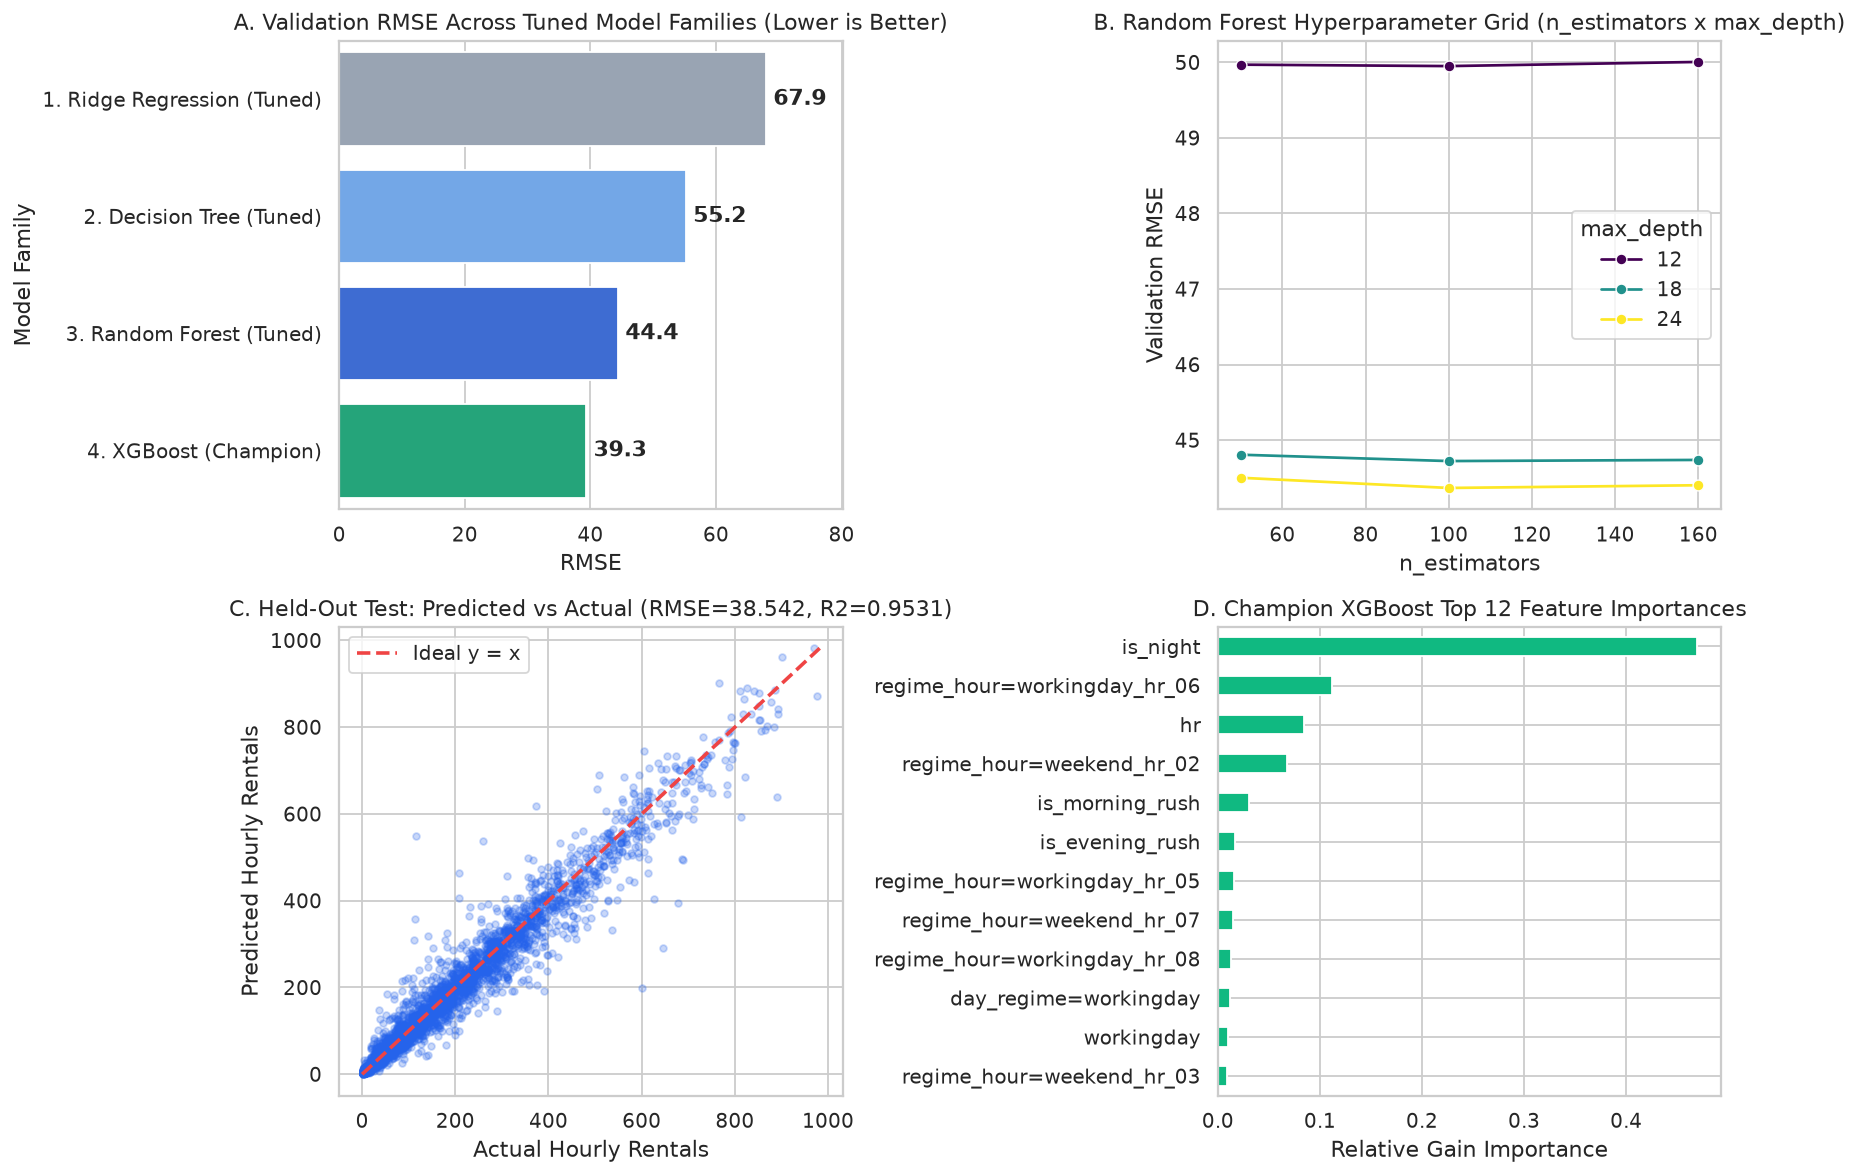

In [11]:
comparison_df = pd.DataFrame([
    {"Model Family": "1. Ridge Regression (Tuned)", "RMSE": best_ridge["RMSE"], "MAE": best_ridge["MAE"], "R2": best_ridge["R2"]},
    {"Model Family": "2. Decision Tree (Tuned)", "RMSE": best_dt["RMSE"], "MAE": best_dt["MAE"], "R2": best_dt["R2"]},
    {"Model Family": "3. Random Forest (Tuned)", "RMSE": best_rf["RMSE"], "MAE": best_rf["MAE"], "R2": best_rf["R2"]},
    {"Model Family": "4. XGBoost (Champion)", "RMSE": best_xgb["RMSE"], "MAE": best_xgb["MAE"], "R2": best_xgb["R2"]},
])
display(comparison_df)

# Retrain champion on full_train (80%) and evaluate on held-out Test (20%)
full_defaults = compute_training_defaults(df_full_train)
dv_final = DictVectorizer(sparse=True)
X_full = dv_final.fit_transform(dataframe_to_feature_dicts(df_full_train, full_defaults))
X_test = dv_final.transform(dataframe_to_feature_dicts(df_test, full_defaults))
y_full_log = np.log1p(df_full_train[TARGET_COLUMN].to_numpy(dtype=float))

best_params = {
    "n_estimators": int(best_xgb["n_estimators"]),
    "learning_rate": float(best_xgb["learning_rate"]),
    "max_depth": int(best_xgb["max_depth"]),
    "min_child_weight": int(best_xgb["min_child_weight"]),
    "subsample": float(best_xgb["subsample"]),
    "colsample_bytree": float(best_xgb["colsample_bytree"]),
}
champion = XGBRegressor(objective="reg:squarederror", random_state=42, n_jobs=-1, **best_params)
champion.fit(X_full, y_full_log)
test_preds = postprocess_predictions(champion.predict(X_test))
test_scores = score_preds(y_test, test_preds)
print(f"FINAL HELD-OUT TEST METRICS -> RMSE: {test_scores['RMSE']} | MAE: {test_scores['MAE']} | R2: {test_scores['R2']}")

top_imp = pd.Series(champion.feature_importances_, index=dv_final.feature_names_).sort_values(ascending=True).tail(12)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2))

sns.barplot(data=comparison_df, x="RMSE", y="Model Family", palette=["#94a3b8", "#60a5fa", "#2563eb", "#10b981"], ax=axes[0, 0])
axes[0, 0].set_title("A. Validation RMSE Across Tuned Model Families (Lower is Better)")
for idx, row in comparison_df.iterrows():
    axes[0, 0].text(row["RMSE"] + 1.2, idx, f"{row['RMSE']:.1f}", va="center", fontweight="bold")
axes[0, 0].set_xlim(0, comparison_df["RMSE"].max() * 1.18)

sns.lineplot(data=rf_df, x="n_estimators", y="RMSE", hue="max_depth", marker="o", palette="viridis", ax=axes[0, 1])
axes[0, 1].set_title("B. Random Forest Hyperparameter Grid (n_estimators x max_depth)")
axes[0, 1].set_ylabel("Validation RMSE")

axes[1, 0].scatter(y_test, test_preds, alpha=0.25, s=14, color="#2563eb")
max_v = max(y_test.max(), test_preds.max())
axes[1, 0].plot([0, max_v], [0, max_v], "--", color="#ef4444", linewidth=2, label="Ideal y = x")
axes[1, 0].set_title(f"C. Held-Out Test: Predicted vs Actual (RMSE={test_scores['RMSE']}, R2={test_scores['R2']})")
axes[1, 0].set_xlabel("Actual Hourly Rentals")
axes[1, 0].set_ylabel("Predicted Hourly Rentals")
axes[1, 0].legend()

top_imp.plot(kind="barh", color="#10b981", ax=axes[1, 1])
axes[1, 1].set_title("D. Champion XGBoost Top 12 Feature Importances")
axes[1, 1].set_xlabel("Relative Gain Importance")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "model_comparison_diagnostics.png", bbox_inches="tight")
plt.show()